# Lab Regressions

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

# For regressions
import re
from regression_functions import *
from rich.progress import track
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

# Read in clean lab data

In [2]:
labs_clean = pd.read_csv("data/clincal_chems_abx_users_clean.csv")

In [3]:
labs_clean.public_client_id.nunique()

2351

In [4]:
statin_users = pd.read_csv('data/arivale_statin_users.csv', dtype={"public_client_id":str, "days_in_program":float})
statin_users = statin_users.sort_values(by="days_in_program")
labs_clean = labs_clean.sort_values(by="days_in_program")

# Merge with all
labs_clean_statin = pd.merge_asof(
    labs_clean, statin_users, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest",
    tolerance=30)

labs_clean_statin.loc[:,'statin_binary'] = labs_clean_statin.loc[:,'statin'].notna().astype(int)

In [5]:
# 1. Remove the column and save its data
col_to_move = labs_clean_statin.pop('statin_binary')

# 2. Insert it back at index 30 (Position 31)
labs_clean_statin.insert(22, 'statin_binary', col_to_move)

In [6]:
labs_clean_statin.columns[0:33]

Index(['public_client_id', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5',
       'days_in_program', 'meds_blood_sugar', 'meds_cholesterol',
       'abx_recency', 'sex', 'age', 'BMI_CALC', 'hx_t2dm', 'hx_gestational',
       'gluc_dysreg', 'eGFR', 'centered_eGFR', 'centered_BMI',
       'abx_recency_three', 'abx_recency_twelve', 'vendor', 'statin_binary',
       'vendor_observation_id', 'observation_id', 'reflexive', 'fasting',
       'days_since_first_call', 'days_since_first_draw', 'month', 'weekday',
       'season', 'A_GRATIO'],
      dtype='object')

In [7]:
labs_mma_small = labs_clean_statin[['public_client_id', 'days_in_program', 'abx_recency', 'hx_t2dm', 'hx_gestational',
                                    'gluc_dysreg', 'vendor', 'HOMOCYSTEINE_SERUM', 'METHYLMALONICACID',
                                    'VITAMIND3_25_OH', 'GLYCOHEMOGLOBINA1C']]

In [8]:
# labs_mma_small.to_csv("data/abx_cohort_labs_glucose_dysreg_hx.csv", index=False)

In [9]:
labs_clean_statin.drop(columns=['statin', 'dosage', 'medications_free_text'], inplace=True)

In [10]:
lab_features = labs_clean_statin.columns[32:]

## Identify which clinical chemistry tests were offered by each vendor

In [11]:
quest = labs_clean[labs_clean['vendor'] == 'Quest']
labcorp = labs_clean[labs_clean['vendor'] == 'LCA']

**Not offered by Quest: Lapcorp only tests**

In [12]:
quest[lab_features].isna().all().sum()

8

In [13]:
not_offered_quest = quest[lab_features].isna().all().index[quest[lab_features].isna().all()].tolist()

In [72]:
not_offered_quest

['DPA',
 'HDLPARTICLENUMBER',
 'LINOLEIC_ACID',
 'LPIR_SCORE',
 'MAGNESIUM_SERUM',
 'OMEGA_3_TOTAL',
 'OMEGA_6_TOTAL',
 'OXLDL']

**Not offered by labcorp: Quest only tests**

In [14]:
labcorp[lab_features].isna().all().sum()

16

In [15]:
not_offered_labcorp = labcorp[lab_features].isna().all().index[labcorp[lab_features].isna().all()].tolist()

In [73]:
not_offered_labcorp

['ANTIOXIDCAP_TOTAL',
 'ARSENIC_BLOOD',
 'BILIRUBIN_DIRECT',
 'BILIRUBIN_INDIRECT',
 'COPPER_RBC',
 'HDLLARGE',
 'LACTICDEHYDROGENASE',
 'LDLMEDIUM',
 'MANGANESE_SERUM',
 'MPV',
 'PAI_1ANTIGEN_QNT',
 'PHOSPHORUSINORGANIC',
 'SELENIUM_SERUM',
 'SUPEROXDISMUTSOD',
 'VITAMIND3_25_OH',
 'ZINC_RBC']

**Offered by both vendors**

In [16]:
individual_vendors = not_offered_labcorp + not_offered_quest

In [17]:
shared_labs = list(set(lab_features) - set(individual_vendors))

# Perform Regressions
Remember, we should test the vendor specific tests separately and then concatenate tables and FDR correct at the end.

In [18]:
len(shared_labs)

70

In [19]:
# shared_labs

In [20]:
len(not_offered_labcorp) # Quest specific

16

In [21]:
# not_offered_labcorp

In [22]:
len(not_offered_quest) # LCA specific

8

In [23]:
# not_offered_quest

## Unadjusted (Model 1)
Here we are just adjusting for batch effects due to vendor. 

In [24]:
forumla_unadjusted_vendor = "{feature} ~ C(abx_recency) + vendor" # This is so I can do the shared labs
forumla_unadjusted = "{feature} ~ C(abx_recency)"
abx_term_three = "C(abx_recency)[T.three]"
abx_term_twelve = "C(abx_recency)[T.twelve]"

### Unadjusted: 3 month group

In [25]:
tests_abx_three_shared = run_tests(shared_labs, labs_clean, forumla_unadjusted_vendor, abx_term_three)
tests_abx_three_quest = run_tests(list(not_offered_labcorp), labs_clean, forumla_unadjusted, abx_term_three)
tests_abx_three_labcorp = run_tests(list(not_offered_quest), labs_clean, forumla_unadjusted, abx_term_three)

# Concat
tests_three = pd.concat([tests_abx_three_shared, tests_abx_three_quest, tests_abx_three_labcorp])

# Apply FDR correctly since we concatenated 3 tables
tests_three.drop(columns='q', inplace=True) 
tests_three.loc[:, "q"] = multipletests(tests_three.p, method="fdr_bh")[1]
tests_three.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
INSULIN,INSULIN,1.234990,0.533053,2.316823,0.189686,2.280294,0.020599,2351.0,0.341236
POTASSIUM,POTASSIUM,-0.041579,0.017828,-2.332194,-0.076540,-0.006618,0.019775,2351.0,0.341236
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.038335,0.017140,-2.236522,-0.071947,-0.004723,0.025411,2351.0,0.341236
ALKALINEPHOSPHATASE,ALKALINEPHOSPHATASE,2.666356,1.164424,2.289849,0.382949,4.949764,0.022118,2351.0,0.341236
VITAMIND_25_OHTOT,VITAMIND_25_OHTOT,2.075791,0.834276,2.488134,0.439796,3.711785,0.012910,2350.0,0.341236


### Unadjusted: 12 months

In [26]:
tests_abx_twelve_shared = run_tests(shared_labs, labs_clean, forumla_unadjusted_vendor, abx_term_twelve)
tests_abx_twelve_quest = run_tests(list(not_offered_labcorp), labs_clean, forumla_unadjusted, abx_term_twelve)
tests_abx_twelve_labcorp = run_tests(list(not_offered_quest), labs_clean, forumla_unadjusted, abx_term_twelve)

# Concat
tests_twelve = pd.concat([tests_abx_twelve_shared, tests_abx_twelve_quest, tests_abx_twelve_labcorp])

# Apply FDR
tests_twelve.drop(columns='q', inplace=True) 
tests_twelve.loc[:, "q"] = multipletests(tests_twelve.p, method="fdr_bh")[1]
tests_twelve.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
QUICKI,QUICKI,-0.007722,0.001821,-4.239910,-0.011294,-0.004151,0.000023,2351.0,0.002183
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.050003,0.015203,-3.289000,-0.079816,-0.020190,0.001020,2351.0,0.047954
TriglycerideHDLRatio,TriglycerideHDLRatio,0.248420,0.091777,2.706784,0.068448,0.428392,0.006843,2350.0,0.124717
CRPHIGHSENSITIVITY,CRPHIGHSENSITIVITY,0.683242,0.267184,2.557201,0.159302,1.207182,0.010614,2351.0,0.124717
WHITECELLCOUNT,WHITECELLCOUNT,0.198239,0.076958,2.575939,0.047326,0.349153,0.010058,2337.0,0.124717


## Adjusted full model
This does not account for t2dm or gestational diabetes

In [27]:
forumla_full_vendor = ("{feature} ~ C(abx_recency) + BMI_CALC + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                        " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor")
forumla_full = ("{feature} ~ C(abx_recency) + BMI_CALC + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")

### 3 months

In [28]:
tests_abx_three_shared_full = run_tests(shared_labs, labs_clean, forumla_full_vendor, abx_term_three)
tests_abx_three_quest_full = run_tests(list(not_offered_labcorp), labs_clean, forumla_full, abx_term_three)
tests_abx_three_labcorp_full = run_tests(list(not_offered_quest), labs_clean, forumla_full, abx_term_three)

# Concat
tests_three_full = pd.concat([tests_abx_three_shared_full, tests_abx_three_quest_full, tests_abx_three_labcorp_full])

# FDR correct
tests_three_full.drop(columns='q', inplace=True) 
tests_three_full.loc[:, "q"] = multipletests(tests_three_full.p, method="fdr_bh")[1]
tests_three_full.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
IL_6,IL_6,2.051305,0.846792,2.422443,0.390735,3.711874,0.015495,2278.0,0.728246
MONOCYTES,MONOCYTES,0.276506,0.110222,2.508621,0.060361,0.492651,0.012188,2335.0,0.728246
POTASSIUM,POTASSIUM,-0.036822,0.017602,-2.091888,-0.071340,-0.002304,0.036556,2351.0,0.931657
SODIUM,SODIUM,-0.231298,0.117829,-1.962997,-0.462359,-0.000238,0.049765,2351.0,0.931657
PLATELETCOUNTTHOUSAND,PLATELETCOUNTTHOUSAND,5.819515,3.086218,1.885646,-0.232517,11.871548,0.059467,2336.0,0.931657


### 12 months

In [29]:
tests_abx_twelve_shared_full = run_tests(shared_labs, labs_clean, forumla_full_vendor, abx_term_twelve)
tests_abx_twelve_quest_full = run_tests(list(not_offered_labcorp), labs_clean, forumla_full, abx_term_twelve)
tests_abx_twelve_labcorp_full = run_tests(list(not_offered_quest), labs_clean, forumla_full, abx_term_twelve)

# Concat
tests_twelve_full = pd.concat([tests_abx_twelve_shared_full, tests_abx_twelve_quest_full, tests_abx_twelve_labcorp_full])

# FDR correct
tests_twelve_full.drop(columns='q', inplace=True) 
tests_twelve_full.loc[:, "q"] = multipletests(tests_twelve_full.p, method="fdr_bh")[1]
tests_twelve_full.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
QUICKI,QUICKI,-0.003118,0.001412,-2.209110,-0.005886,-0.000350,0.027264,2351.0,0.625683
MONOCYTES,MONOCYTES,0.238852,0.097035,2.461511,0.048568,0.429136,0.013908,2335.0,0.625683
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.037965,0.014515,-2.615672,-0.066428,-0.009503,0.008963,2351.0,0.625683
BILIRUBIN_DIRECT,BILIRUBIN_DIRECT,-0.015210,0.007125,-2.134775,-0.029210,-0.001211,0.033281,498.0,0.625683
MONOCYTESABSOLUTE,MONOCYTESABSOLUTE,0.014603,0.006476,2.255002,0.001904,0.027302,0.024226,2335.0,0.625683


## Model 3: Now account for history of T2DM or Gestational Diabetes
No interaction term yet!

In [30]:
forumla_hx_vendor = ("{feature} ~ C(abx_recency) + BMI_CALC + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                        " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor + C(hx_t2dm) + C(hx_gestational)")
forumla_hx = ("{feature} ~ C(abx_recency) + BMI_CALC + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)"
                " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + C(hx_t2dm) + C(hx_gestational)")

## Three months

In [31]:
tests_abx_three_shared_hx = run_tests(shared_labs, labs_clean, forumla_hx_vendor, abx_term_three)
tests_abx_three_quest_hx= run_tests(list(not_offered_labcorp), labs_clean, forumla_hx, abx_term_three)
tests_abx_three_labcorp_hx= run_tests(list(not_offered_quest), labs_clean, forumla_hx, abx_term_three)

# Concat
tests_three_hx= pd.concat([tests_abx_three_shared_hx, tests_abx_three_quest_hx, tests_abx_three_labcorp_hx])

# FDR correct
tests_three_hx.drop(columns='q', inplace=True) 
tests_three_hx.loc[:, "q"] = multipletests(tests_three_hx.p, method="fdr_bh")[1]
tests_three_hx.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
IL_6,IL_6,2.043551,0.848094,2.409582,0.380428,3.706675,0.016050,2278.0,0.754362
MONOCYTES,MONOCYTES,0.270986,0.110176,2.459560,0.054931,0.487040,0.013983,2335.0,0.754362
CARBONDIOXIDE_CO2_,CARBONDIOXIDE_CO2_,0.064472,0.117702,0.547762,-0.166338,0.295283,0.583907,2351.0,0.945080
ZINC_RBC,ZINC_RBC,-0.116228,0.224123,-0.518592,-0.556609,0.324153,0.604284,497.0,0.945080
LDLPARTICLENUMBER,LDLPARTICLENUMBER,23.062616,23.614969,0.976610,-23.245908,69.371141,0.328864,2349.0,0.945080


## Twelve months

In [32]:
tests_abx_twelve_shared_hx = run_tests(shared_labs, labs_clean, forumla_hx_vendor, abx_term_twelve)
tests_abx_twelve_quest_hx = run_tests(list(not_offered_labcorp), labs_clean, forumla_hx, abx_term_twelve)
tests_abx_twelve_labcorp_hx = run_tests(list(not_offered_quest), labs_clean, forumla_hx, abx_term_twelve)

# Concat
tests_twelve_hx = pd.concat([tests_abx_twelve_shared_hx, tests_abx_twelve_quest_hx, tests_abx_twelve_labcorp_hx])

# FDR correct
tests_twelve_hx.drop(columns='q', inplace=True) 
tests_twelve_hx.loc[:, "q"] = multipletests(tests_twelve_hx.p, method="fdr_bh")[1]
tests_twelve_hx.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
MONOCYTES,MONOCYTES,0.228333,0.097098,2.351569,0.037925,0.418741,0.018778,2335.0,0.738799
MONOCYTESABSOLUTE,MONOCYTESABSOLUTE,0.013966,0.006458,2.162600,0.001302,0.026630,0.030674,2335.0,0.738799
BILIRUBIN_DIRECT,BILIRUBIN_DIRECT,-0.015242,0.007167,-2.126602,-0.029324,-0.001159,0.033961,498.0,0.738799
QUICKI,QUICKI,-0.002901,0.001407,-2.062214,-0.005659,-0.000142,0.039298,2351.0,0.738799
BILIRUBIN_TOTAL,BILIRUBIN_TOTAL,-0.037908,0.014539,-2.607313,-0.066418,-0.009397,0.009184,2351.0,0.738799


# Model 4: Interaction term with "glucose dysregulation" phenotypes
This term lumps together individuals with a glucose lowering medication, history of t2dm, and history of gestational diabetes.

In [33]:
#### Glucose dysregulation lumped together ####
forumla_gintv = ("{feature} ~ C(abx_recency)*C(gluc_dysreg) + BMI_CALC + sex + age + C(meds_cholesterol)"
                        " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor")
forumla_gint = ("{feature} ~ C(abx_recency)*C(gluc_dysreg) + BMI_CALC + sex + age + C(meds_cholesterol)"
                " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")

gint_three = "C(abx_recency)[T.three]:C(gluc_dysreg)[T.1]"
gint_twelve = "C(abx_recency)[T.twelve]:C(gluc_dysreg)[T.1]"

In [34]:
tests_abx_three_shared_gint = run_tests(shared_labs, labs_clean, forumla_gintv, gint_three)
tests_abx_three_quest_gint = run_tests(list(not_offered_labcorp), labs_clean, forumla_gint, gint_three)
tests_abx_three_labcorp_gint = run_tests(list(not_offered_quest), labs_clean, forumla_gint, gint_three)

# Concat
tests_three_gint = pd.concat([tests_abx_three_shared_gint, tests_abx_three_quest_gint, tests_abx_three_labcorp_gint])

# FDR correct
tests_three_gint.drop(columns='q', inplace=True) 
tests_three_gint.loc[:, "q"] = multipletests(tests_three_gint.p, method="fdr_bh")[1]
tests_three_gint.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
METHYLMALONICACID,METHYLMALONICACID,96.841027,21.597993,4.483798,54.487412,139.194642,0.000008,2313.0,0.000723
VITAMIND_25_OHTOT,VITAMIND_25_OHTOT,-9.366294,3.019323,-3.102117,-15.287130,-3.445458,0.001944,2350.0,0.091388
UREANITROGEN,UREANITROGEN,-2.135417,0.721569,-2.959410,-3.550400,-0.720435,0.003113,2351.0,0.097550
CREATININEENZ_SER,CREATININEENZ_SER,-0.074581,0.028832,-2.586737,-0.131120,-0.018042,0.009749,2351.0,0.131947
HOMOCYSTEINE_SERUM,HOMOCYSTEINE_SERUM,1.666554,0.621692,2.680676,0.447427,2.885682,0.007399,2346.0,0.131947


In [35]:
# sens_analysis_three = tests_three_gint[tests_three_gint.q <0.2].copy()
# sens_analysis_three.sort_values(by='q')

In [36]:
tests_abx_twelve_shared_gint = run_tests(shared_labs, labs_clean, forumla_gintv, gint_twelve)
tests_abx_twelve_quest_gint = run_tests(list(not_offered_labcorp), labs_clean, forumla_gint, gint_twelve)
tests_abx_twelve_labcorp_gint = run_tests(list(not_offered_quest), labs_clean, forumla_gint, gint_twelve)

# Concat
tests_twelve_gint = pd.concat([tests_abx_twelve_shared_gint, tests_abx_twelve_quest_gint, tests_abx_twelve_labcorp_gint])

# FDR correct
tests_twelve_gint.drop(columns='q', inplace=True) 
tests_twelve_gint.loc[:, "q"] = multipletests(tests_twelve_gint.p, method="fdr_bh")[1]
tests_twelve_gint.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
GLYCOHEMOGLOBINA1C,GLYCOHEMOGLOBINA1C,-0.301822,0.077826,-3.878183,-0.454437,-0.149208,0.000108,2351.0,0.010166
CREATININEENZ_SER,CREATININEENZ_SER,-0.087291,0.023796,-3.668290,-0.133954,-0.040627,0.000250,2351.0,0.011733
GLUCOSE,GLUCOSE,-8.977087,2.613874,-3.434399,-14.102844,-3.851329,0.000604,2351.0,0.018933
UREANITROGEN,UREANITROGEN,-1.865951,0.595534,-3.133241,-3.033782,-0.698121,0.001750,2351.0,0.041133
ZINC_RBC,ZINC_RBC,2.360526,0.872549,2.705321,0.646047,4.075005,0.007066,497.0,0.132842


In [37]:
# sens_analysis_twelve = tests_twelve_gint[tests_twelve_gint.q <0.2].copy()

Interesting results. So far these are my thoughts:
- Why don’t we see more convergent results between the groups? There’s one shared, urea nitrogen, but not many. I would have expected the results to be more convergent, with stronger signal in the 3 months than 12 months group (trend we've been seeing so far in the microbiome and metabolome).
- It’s cool to see Vitamin D 25 OH on there; helps boost what we see in metBMI. I wouldn’t be surprised if the metBMI of the gluc_dysreg > their actual BMI
- What are outliers versus appropriate values (for example with MMA below). Should I employ data cleaning to remove outliers in all columns before regression?
- Is any of this driven by an abx and statin signal?

<Axes: xlabel='gluc_dysreg', ylabel='METHYLMALONICACID'>

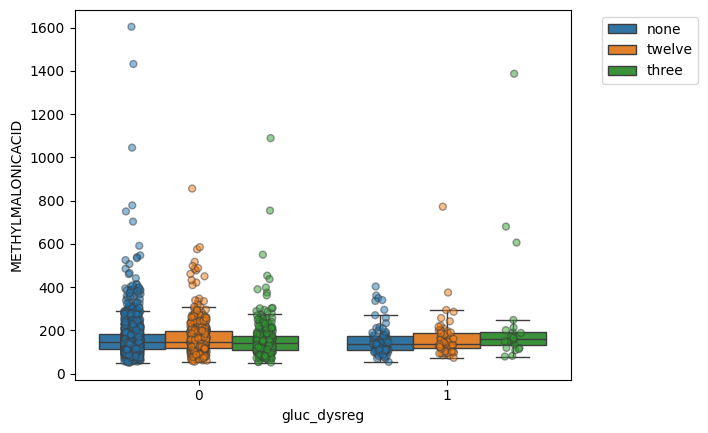

In [38]:
sns.boxplot(data=labs_clean, x='gluc_dysreg', y='METHYLMALONICACID',
            hue='abx_recency', hue_order=['none', 'twelve', 'three'], showfliers=False)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sns.stripplot(data=labs_clean, x='gluc_dysreg', y ='METHYLMALONICACID',
              hue='abx_recency', hue_order=['none', 'twelve', 'three'], alpha=0.5,
              jitter=True, dodge=True, legend=False,
              marker="o",          # Standard circle marker
              facecolors="none",   # Removes the fill (makes it open)
              linewidth=1)

<Axes: xlabel='gluc_dysreg', ylabel='METHYLMALONICACID'>

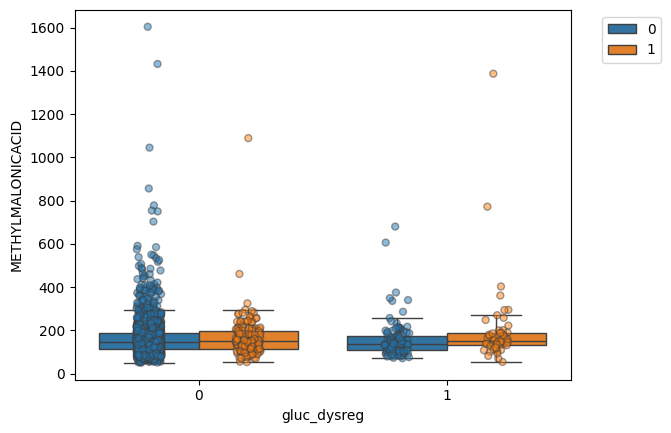

In [39]:
sns.boxplot(data=labs_clean_statin, x='gluc_dysreg', y='METHYLMALONICACID',
            hue='statin_binary', showfliers=False)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sns.stripplot(data=labs_clean_statin, x='gluc_dysreg', y ='METHYLMALONICACID',
              hue='statin_binary', alpha=0.5,
              jitter=True, dodge=True, legend=False,
              marker="o",          # Standard circle marker
              facecolors="none",   # Removes the fill (makes it open)
              linewidth=1)

What do our results have in common? Are there any patterns that we could pick up?

In [40]:
# sens_analysis_three.sort_values(by='feature')
# sens_analysis_three.rename(columns={'feature':'feature_three'}, inplace=True)

In [41]:
# sens_analysis_three

In [42]:
# sens_analysis_twelve

In [43]:
# sens_analysis_twelve.rename(columns={'feature':'feature_twelve'}, inplace=True)
# sens_analysis_twelve.sort_values(by='feature')

In [44]:
# set(sens_analysis_twelve.feature.tolist() + sens_analysis_three.feature.tolist()) 
# set(sens_analysis_three.feature) 

In [45]:
# ---- assumptions you should verify against your df ----
FEATURES = ["METHYLMALONICACID", "GLYCOHEMOGLOBINA1C", "GLUCOSE"] # the FDR<0.05 hits
ABX_LEVELS = ["none", "twelve", "three"] # <-- EDIT: use your actual category labels, 
DYS_LEVELS = [0, 1] # with the reference level first

CONT_COVARS = ["BMI_CALC", "age", "PC1", "PC2", "PC3", "PC4", "PC5", "centered_eGFR"]

# categorical nuisance vars pinned to a chosen reference cell (document the choice):
CAT_FIXED={"sex": None, "meds_cholesterol": "No", "vendor": None} # None => use modal level

FORMULA = ("{feature} ~ C(abx_recency)*C(gluc_dysreg) + BMI_CALC + sex + age + C(meds_cholesterol) + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor")

In [46]:
def reference_grid(df):
    base={c: df[c].mean() for c in CONT_COVARS}
    for k, v in CAT_FIXED.items():
        base[k] = df[k].mode().iloc[0] if v is None else v
    rows = []
    for abx in ABX_LEVELS:
        for dys in DYS_LEVELS:
            rows.append({**base, "abx_recency": abx, "gluc_dysreg": dys})
    return pd.DataFrame(rows)

def emm_for_feature(df, feature):
    d = df.dropna(subset=[feature]).copy()
    model = smf.ols(FORMULA.format(feature=feature), data=d).fit()
    grid = reference_grid(d)
    pred = model.get_prediction(grid).summary_frame(alpha=0.05) # mean, mean_ci_low/high
    out = pd.concat([grid[["abx_recency", "gluc_dysreg"]].reset_index(drop=True),
                     pred[["mean", "mean_ci_lower", "mean_ci_upper"]]], axis=1)
    out["feature"] = feature
    out["n_model"] = int(model.nobs)
    return out, model

In [47]:
def simple_effects(emm, feature):
    """dysreg(1) - dysreg(0) within each abx stratum -> the 'story' per window."""
    w = emm.pivot(index="abx_recency", columns="gluc_dysreg", values="mean")
    eff = (w[1] - w[0]).rename("dysreg_minus_nondysreg").reset_index()
    eff["feature"] = feature
    return eff


=== METHYLMALONICACID (n=2313) ===
abx_recency  gluc_dysreg    mean  mean_ci_lower  mean_ci_upper           feature  n_model
       none            0 156.268        150.201        162.335 METHYLMALONICACID     2313
       none            1 148.416        128.439        168.393 METHYLMALONICACID     2313
     twelve            0 159.482        150.481        168.484 METHYLMALONICACID     2313
     twelve            1 166.417        141.547        191.288 METHYLMALONICACID     2313
      three            0 151.354        140.961        161.746 METHYLMALONICACID     2313
      three            1 240.342        203.842        276.843 METHYLMALONICACID     2313

=== GLYCOHEMOGLOBINA1C (n=2351) ===
abx_recency  gluc_dysreg  mean  mean_ci_lower  mean_ci_upper            feature  n_model
       none            0 5.470          5.441          5.498 GLYCOHEMOGLOBINA1C     2351
       none            1 6.409          6.315          6.504 GLYCOHEMOGLOBINA1C     2351
     twelve            0 5.475

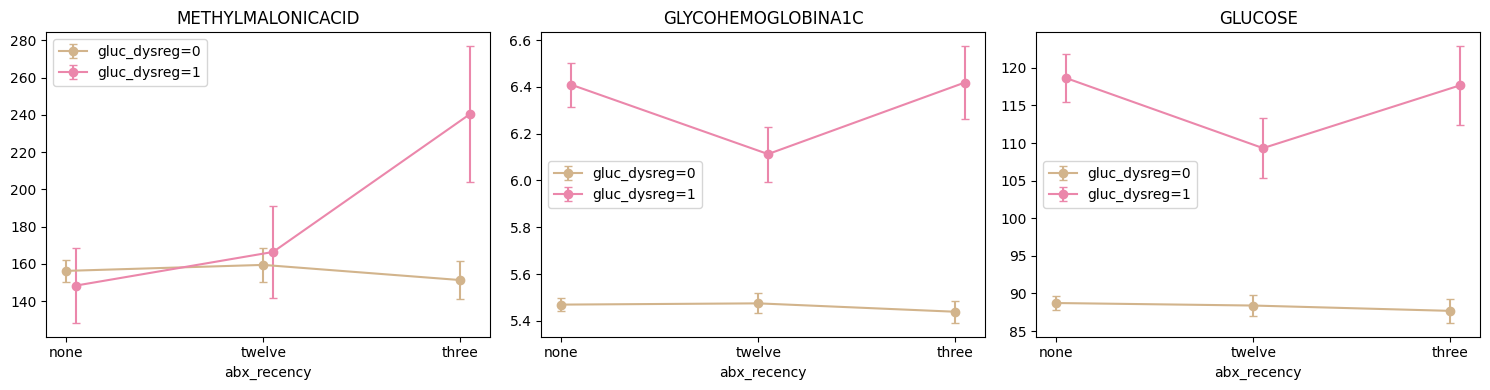

In [48]:
all_emm, all_eff = [], []

for feat in FEATURES:
    emm, mdl = emm_for_feature(labs_clean, feat) #<-- df = your dataframe
    all_emm.append(emm)
    all_eff.append(simple_effects(emm, feat))
    print(f"\n=== {feat} (n={emm['n_model'].iloc[0]}) ===")
    print(emm.round(3).to_string(index=False))

emm_tbl = pd.concat(all_emm, ignore_index=True)
eff_tbl = pd.concat(all_eff, ignore_index=True)
print("\n=== dysreg simple effect by abx window (does the arc hold?) ===")
print(eff_tbl.round(3).to_string(index=False))

# ---- plot: EMM +/- 95% CI, one panel per feature ----
fig, axes = plt.subplots(1, len(FEATURES), figsize=(5 * len(FEATURES), 4))
for ax, feat in zip(np.atleast_1d(axes), FEATURES):
    sub = emm_tbl[emm_tbl.feature == feat]
    for dys, color in zip(DYS_LEVELS, ["#D2B48C", "#EB87AB"]):
        s = sub[sub.gluc_dysreg == dys]
        x = np.arange(len(ABX_LEVELS))
        s = s.set_index("abx_recency").loc[ABX_LEVELS].reset_index()
        ax.errorbar(x + 0.05 * dys, s["mean"],
                    yerr=[s["mean"] - s["mean_ci_lower"], s["mean_ci_upper"] - s["mean"]],
                    marker="o", capsize=3, label=f"gluc_dysreg={dys}", color=color)
    ax.set_xticks(range(len(ABX_LEVELS))); ax.set_xticklabels(ABX_LEVELS)
    ax.set_title(feat); ax.set_xlabel("abx_recency"); ax.legend()
fig.tight_layout()
# fig.savefig("emm_2x3_grid.png", dpi=150)
# print("\nsaved emm_2x3_grid.png")

<Axes: xlabel='gluc_dysreg', ylabel='METHYLMALONICACID'>

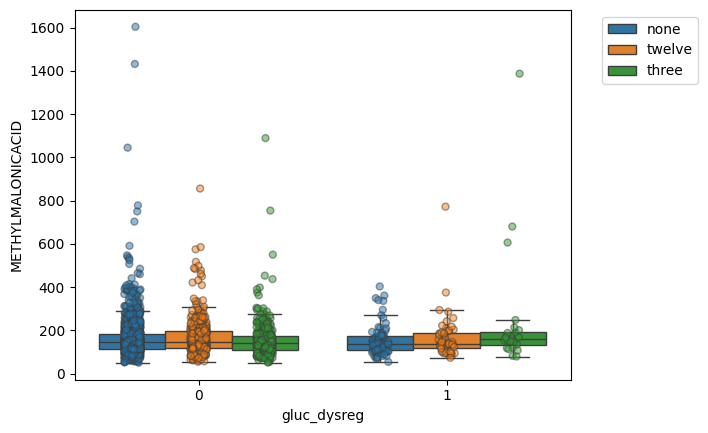

In [49]:
sns.boxplot(data=labs_clean, x='gluc_dysreg', y='METHYLMALONICACID',
            hue='abx_recency', hue_order=['none', 'twelve', 'three'], showfliers=False)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sns.stripplot(data=labs_clean, x='gluc_dysreg', y ='METHYLMALONICACID',
              hue='abx_recency', hue_order=['none', 'twelve', 'three'], alpha=0.5,
              jitter=True, dodge=True, legend=False,
              marker="o",          # Standard circle marker
              facecolors="none",   # Removes the fill (makes it open)
              linewidth=1)

# Three way interaction before data cleaning

In [50]:
forumla_gintv_stat = ("{feature} ~ C(abx_recency)*C(gluc_dysreg)*C(statin_binary) + BMI_CALC + sex + age"
                        " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor")
forumla_gint_stat = ("{feature} ~ C(abx_recency)*C(gluc_dysreg)*C(statin_binary) + BMI_CALC + sex + age"
                " + PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR")

gint_three_stat = "C(abx_recency)[T.three]:C(gluc_dysreg)[T.1]:C(statin_binary)[T.1]"
gint_twelve_stat = "C(abx_recency)[T.twelve]:C(gluc_dysreg)[T.1]:C(statin_binary)[T.1]"

### Test the 3 way interaction term

In [51]:
tests_abx_three_shared_gint_stat = run_tests(shared_labs, labs_clean_statin, forumla_gintv_stat, gint_three_stat)
tests_abx_three_quest_gint_stat= run_tests(list(not_offered_labcorp), labs_clean_statin, forumla_gint_stat, gint_three_stat)
tests_abx_three_labcorp_gint_stat= run_tests(list(not_offered_quest), labs_clean_statin, forumla_gint_stat, gint_three_stat)

# Concat
tests_three_gint_stat= pd.concat([tests_abx_three_shared_gint_stat, tests_abx_three_quest_gint_stat, tests_abx_three_labcorp_gint_stat])

# FDR correct
tests_three_gint_stat.drop(columns='q', inplace=True) 
tests_three_gint_stat.loc[:, "q"] = multipletests(tests_three_gint_stat.p, method="fdr_bh")[1]
tests_three_gint_stat.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
CREATININEENZ_SER,CREATININEENZ_SER,-3.118999e-01,6.479487e-02,-4.813651,-4.389615e-01,-1.848382e-01,0.000002,2351.0,0.000148
HOMA_IR,HOMA_IR,3.460877e+00,1.382061e+00,2.504142,7.506792e-01,6.171074e+00,0.012343,2351.0,0.580109
HDLLARGE,HDLLARGE,1.074009e-12,5.166716e-13,2.078708,5.878093e-14,2.089238e-12,0.038177,498.0,0.798823
MANGANESE_SERUM,MANGANESE_SERUM,1.443612e-16,7.145863e-17,2.020206,3.949283e-18,2.847730e-16,0.043919,498.0,0.798823
PHOSPHORUSINORGANIC,PHOSPHORUSINORGANIC,3.243565e-16,1.508191e-16,2.150633,2.800614e-17,6.207069e-16,0.032006,498.0,0.798823


In [52]:
tests_abx_twelve_shared_gint_stat= run_tests(shared_labs, labs_clean_statin, forumla_gintv_stat, gint_twelve_stat)
tests_abx_twelve_quest_gint_stat= run_tests(list(not_offered_labcorp), labs_clean_statin, forumla_gint_stat, gint_twelve_stat)
tests_abx_twelve_labcorp_gint_stat= run_tests(list(not_offered_quest), labs_clean_statin, forumla_gint_stat, gint_twelve_stat)

# Concat
tests_twelve_gint_stat = pd.concat([tests_abx_twelve_shared_gint_stat, tests_abx_twelve_quest_gint_stat, tests_abx_twelve_labcorp_gint_stat])

# FDR correct
tests_twelve_gint_stat.drop(columns='q', inplace=True) 
tests_twelve_gint_stat.loc[:, "q"] = multipletests(tests_twelve_gint_stat.p, method="fdr_bh")[1]
tests_twelve_gint_stat.sort_values(by='q').head()

Output()

Output()

Output()

,feature,beta,se,t_statistic,conf_low,conf_high,p,n,q
CREATININEENZ_SER,CREATININEENZ_SER,-0.307457,0.053654,-5.730363,-0.412671,-0.202242,1.131723e-08,2351.0,0.000001
MAGNESIUM_SERUM,MAGNESIUM_SERUM,-0.189603,0.068943,-2.750146,-0.324818,-0.054387,6.015884e-03,1839.0,0.282747
REDCELLCOUNT,REDCELLCOUNT,0.206535,0.143338,1.440897,-0.074549,0.487620,1.497491e-01,2337.0,0.759818
HEMATOCRIT,HEMATOCRIT,2.325297,1.157795,2.008384,0.054874,4.595721,4.471841e-02,2337.0,0.759818
EOSINOPHILSABSOLUTE,EOSINOPHILSABSOLUTE,0.063606,0.045435,1.399947,-0.025491,0.152703,1.616634e-01,2335.0,0.759818


## Look at metformin usage re: MMA hit

In [57]:
check_meds = adi.get_snapshot('assessments_medications')[[
    'public_client_id','days_in_program','assessment_vitals_prescriptions_text'
]].copy()

/users/cperez/miniconda3/envs/arivale-py/lib/python3.12/site-packages/arivale_data_interface/snapshots_interface.py:271: DeprecationWarning:

`assessments_medications` is slated for deprecation and will be part of `assessments` with raw data will be available in `assessments_raw`



In [60]:
metformin_pat = re.compile(
    r"""
    \b(?:
        met\s?a?\s?(?:f|ph)ormin       # metformin, metaformin, met formin, metphormin
      | glucophage(?:\s*xr)?
      | glumetza | fortamet | riomet
      # ---- fixed-dose combos that CONTAIN metformin ----
      | janumet(?:\s*xr)?
      | kombiglyze(?:\s*xr)?
      | jentadueto(?:\s*xr)?
      | invokamet(?:\s*xr)?
      | synjardy(?:\s*xr)?
      | xigduo(?:\s*xr)?
      | segluromet
      | trijardy(?:\s*xr)?
      | actoplus\s*met
      | prandimet
      | glucovance
      | metaglip
      | kazano
    )\b
    """,
    re.IGNORECASE | re.VERBOSE,
)

In [61]:
check_meds.set_index('public_client_id', inplace=True)

In [62]:
mask = check_meds['assessment_vitals_prescriptions_text'].fillna("").str.contains(metformin_pat)

In [63]:
mask.sum()

220

In [ ]:
# Should look to see if metformin use if driving the low MMA

## Pointed test to look at statin*abx interaction on HbA1c re: tom's paper

In [65]:
labs_clean_statin['abx_year'] = labs_clean_statin['abx_recency'].apply(lambda x: "none" if x == "none" else "past_year")

In [66]:
hba1c_statin_abx = ('GLYCOHEMOGLOBINA1C ~ C(sex) + age + BMI_CALC + centered_eGFR + '
                    'PC1 + PC2 + PC3 + PC4 + PC5 + C(vendor) +'
                    'C(statin_binary)*C(abx_year) + C(meds_blood_sugar) + C(hx_t2dm) + C(hx_gestational)')

hba1c_model = ols(hba1c_statin_abx, data=labs_clean_statin).fit()
hba1c_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     GLYCOHEMOGLOBINA1C   R-squared:                       0.486
Model:                            OLS   Adj. R-squared:                  0.483
Method:                 Least Squares   F-statistic:                     138.0
Date:                Mon, 20 Jul 2026   Prob (F-statistic):               0.00
Time:                        22:11:29   Log-Likelihood:                -1085.8
No. Observations:                2351   AIC:                             2206.
Df Residuals:                    2334   BIC:                             2304.
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
==================================================================================================================
                                                     coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
Intercept                                          4.7640      0.055     86.757      0.000       4.656       4.872
C(sex)[T.M]                                        0.0243      0.017      1.436      0.151      -0.009       0.058
C(vendor)[T.Quest]                                -0.1851      0.020     -9.059      0.000      -0.225      -0.145
C(statin_binary)[T.1]                              0.0474      0.039      1.228      0.220      -0.028       0.123
C(abx_year)[T.past_year]                          -0.0138      0.017     -0.790      0.430      -0.048       0.020
C(meds_blood_sugar)[T.Yes]                         0.3944      0.054      7.343      0.000       0.289       0.500
C(hx_t2dm)[T.Yes]                                  1.2824      0.058     22.057      0.000       1.168       1.396
C(hx_gestational)[T.Yes]                           0.1051      0.053      1.969      0.049       0.000       0.210
C(statin_binary)[T.1]:C(abx_year)[T.past_year]     0.0026      0.054      0.048      0.962      -0.104       0.109
age                                                0.0091      0.001     10.814      0.000       0.007       0.011
BMI_CALC                                           0.0105      0.001      7.955      0.000       0.008       0.013
centered_eGFR                                      0.0003      0.001      0.383      0.702      -0.001       0.002
PC1                                               -0.4316      0.059     -7.294      0.000      -0.548      -0.316
PC2                                                0.2471      0.052      4.742      0.000       0.145       0.349
PC3                                                0.2695      0.057      4.716      0.000       0.157       0.382
PC4                                                0.1041      0.058      1.782      0.075      -0.010       0.219
PC5                                               -0.1493      0.054     -2.753      0.006      -0.256      -0.043
==============================================================================
Omnibus:                     1713.518   Durbin-Watson:                   1.974
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           108499.115
Skew:                           2.819   Prob(JB):                         0.00
Kurtosis:                      35.800   Cond. No.                         509.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [67]:
pd.crosstab(labs_clean_statin.abx_year, labs_clean_statin.statin_binary)

statin_binary,0,1
abx_year,,
none,1338,118
past_year,786,109


1_none vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.560e-02 (ns) U_stat=5.446e+03
0_none vs. 0_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.096e-01 U_stat=5.189e+05
0_none vs. 1_none: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.274e-08 U_stat=5.459e+04
0_past_year vs. 1_past_year: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.584e-16 U_stat=2.262e+04


(<Axes: xlabel='statin_binary', ylabel='GLYCOHEMOGLOBINA1C'>,
  <statannotations.Annotation.Annotation at 0x7ba2d2b07350>])

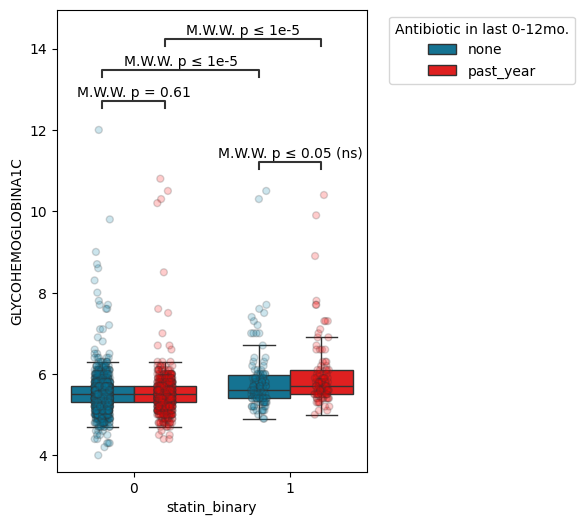

In [70]:
abx_order = ['none', 'past_year']
abx_year_pal = {'none': "#007ea7", 'past_year': 'red'}

statin_order = [0, 1]
comparisons=[
    ((0, 'none'), (0, 'past_year')),
    ((1,'none'),(1, 'past_year')),
    ((0, 'none'), (1, 'none')),
    ((0, 'past_year'), (1, 'past_year')),
    ]

fig, ax = plt.subplots(1, 1, figsize=(4, 6))
sns.boxplot(data=labs_clean_statin, x='statin_binary', y ='GLYCOHEMOGLOBINA1C',
            hue='abx_year', showfliers=False, palette=abx_year_pal,
            order=statin_order, hue_order=abx_order)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Antibiotic in last 0-12mo.")

sns.stripplot(data=labs_clean_statin, x='statin_binary', y ='GLYCOHEMOGLOBINA1C',
              hue='abx_year',  palette=abx_year_pal, 
              order=statin_order, hue_order=abx_order,
              alpha=0.2, jitter=True, dodge=True, legend=False,
              marker="o",          # Standard circle marker
              facecolors="none",   # Removes the fill (makes it open)
              linewidth=1)

# Annotate
annotator = Annotator(ax, comparisons, data=labs_clean_statin, x='statin_binary', y='GLYCOHEMOGLOBINA1C',
               order=statin_order, hue='abx_year', hue_order=abx_order)
annotator.configure(test='Mann-Whitney', verbose=2, comparisons_correction="BH", text_format='simple')
annotator.apply_test() 
annotator.annotate()